In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# 1. Загрузка данных
digits = load_digits()
X, y = digits.data, digits.target
print(f"Анхны өгөгдлийн матриц: {X.shape}")

# Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Анхны өгөгдлийн матриц: (1797, 64)


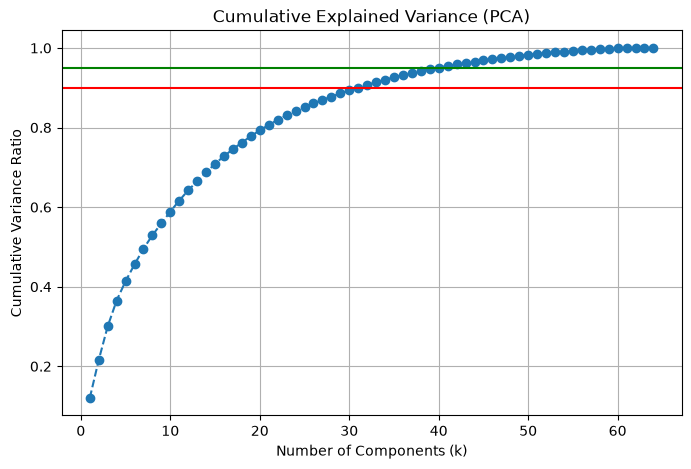

90% дисперсийг хадгалахад шаардлагатай k: 31
95% дисперсийг хадгалахад шаардлагатай k: 40


In [2]:
# Обучение PCA на всех 64 компонентах
pca = PCA().fit(X_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)

# Построение графика
plt.figure(figsize=(8, 5))
plt.plot(range(1, 65), cum_var, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle='-')
plt.axhline(y=0.95, color='g', linestyle='-')
plt.title('Cumulative Explained Variance (PCA)')
plt.xlabel('Number of Components (k)')
plt.ylabel('Cumulative Variance Ratio')
plt.grid(True)
plt.show()

# Поиск k для 90% и 95%
k1 = np.argmax(cum_var >= 0.90) + 1
k2 = np.argmax(cum_var >= 0.95) + 1
print(f"90% дисперсийг хадгалахад шаардлагатай k: {k1}")
print(f"95% дисперсийг хадгалахад шаардлагатай k: {k2}")

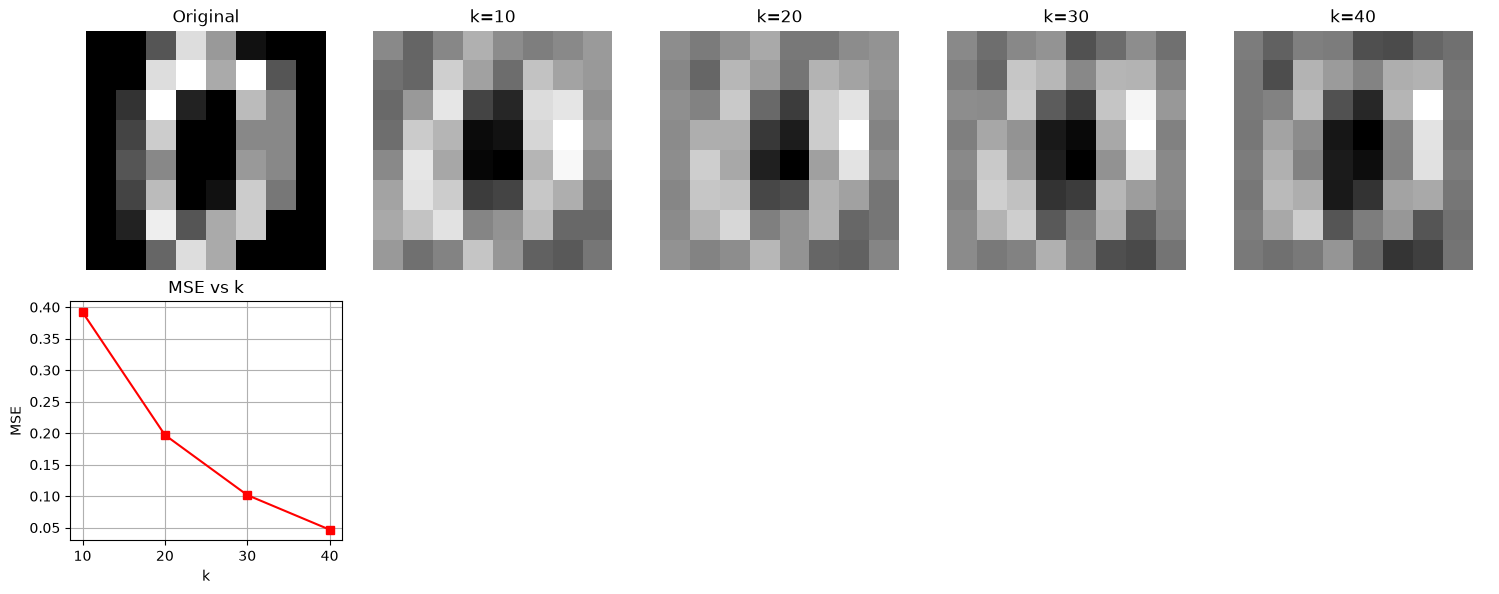

MSE утгууд: [0.3919845194413313, 0.19716569924267321, 0.10178570729777545, 0.04691365839210274]


In [3]:
k_values = [10, 20, 30, 40]
mse_values = []

fig, axes = plt.subplots(2, len(k_values) + 1, figsize=(15, 6))
# Оригинал
axes[0, 0].imshow(X[0].reshape(8, 8), cmap='gray')
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

for i, k in enumerate(k_values):
    pca_k = PCA(n_components=k)
    X_pca = pca_k.fit_transform(X_scaled)
    X_reconstructed = pca_k.inverse_transform(X_pca)
    
    # MSE
    mse = mean_squared_error(X_scaled, X_reconstructed)
    mse_values.append(mse)
    
    # Визуализация восстановленного изображения
    axes[0, i+1].imshow(X_reconstructed[0].reshape(8, 8), cmap='gray')
    axes[0, i+1].set_title(f'k={k}')
    axes[0, i+1].axis('off')

# График MSE от k
axes[1, 0].plot(k_values, mse_values, marker='s', color='r')
axes[1, 0].set_title('MSE vs k')
axes[1, 0].set_xlabel('k')
axes[1, 0].set_ylabel('MSE')
axes[1, 0].grid(True)

for i in range(1, len(k_values) + 1):
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()
print("MSE утгууд:", mse_values)

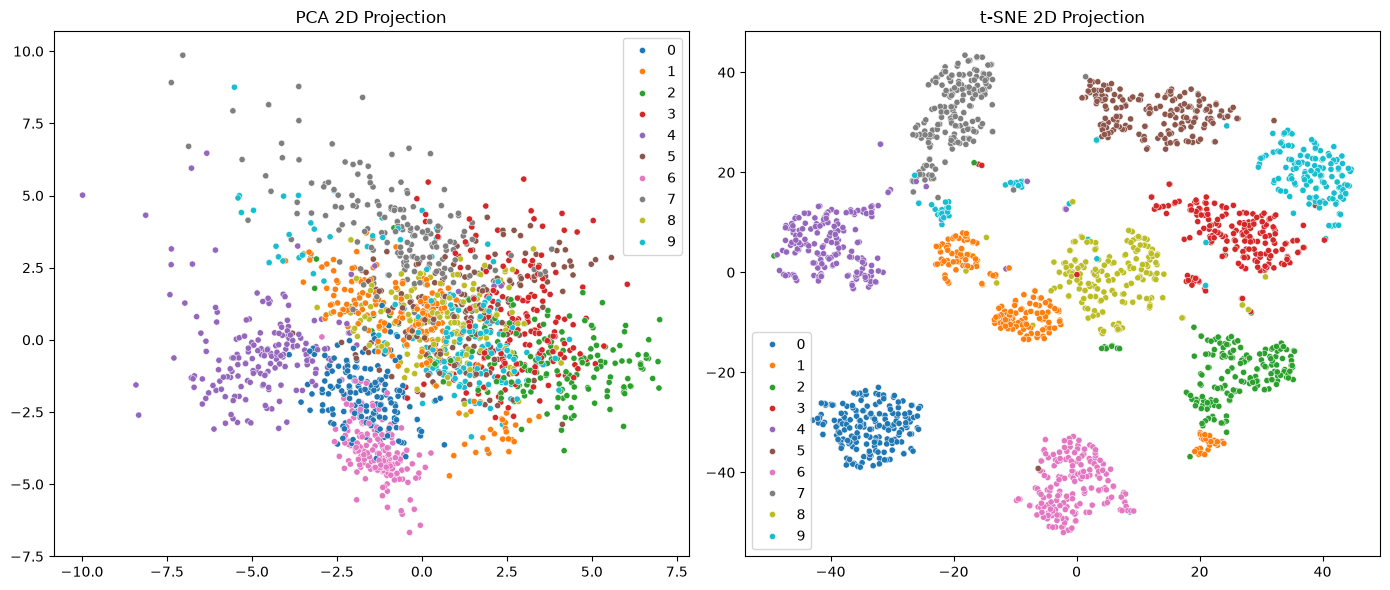

In [4]:
# PCA 2D
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# t-SNE 2D
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne_2d = tsne.fit_transform(X_scaled)

# Визуализация
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=y, palette='tab10', legend='full', s=20)
plt.title('PCA 2D Projection')

plt.subplot(1, 2, 2)
sns.scatterplot(x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=y, palette='tab10', legend='full', s=20)
plt.title('t-SNE 2D Projection')

plt.tight_layout()
plt.show()